Image shape: (1054, 2800, 3)


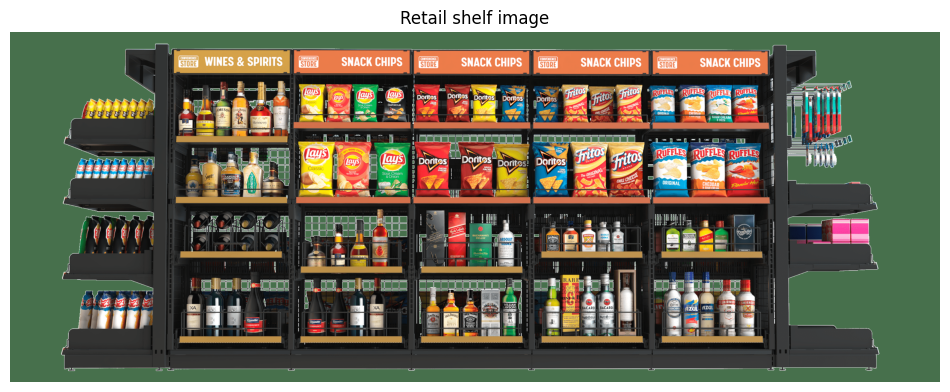

Model loaded.


In [18]:
%matplotlib inline
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

img_path = "../data/retail.png"
img = cv2.imread(img_path)
if img is None:
    raise FileNotFoundError(f"Could not read {img_path}")

print("Image shape:", img.shape)

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Retail shelf image")
plt.axis("off")
plt.show()

model = YOLO("yolov8n.pt")
print("Model loaded.")

In [9]:
model = YOLO("yolov8n.pt")
print("Model loaded. Names available:", len(model.names))

Model loaded. Names available: 80


In [10]:
results = model(str(img_path), conf=0.15, verbose=False)
boxes = results[0].boxes

n_detections = len(boxes) if boxes is not None else 0
print(f"Raw detections at conf ≥ 0.15: {n_detections}")

Raw detections at conf ≥ 0.15: 37


In [11]:
if boxes is not None and len(boxes) > 0:
    cls_ids  = boxes.cls.cpu().numpy().astype(int)
    conf_arr = boxes.conf.cpu().numpy()

    unique, counts = np.unique(cls_ids, return_counts=True)
    print("Detected classes (before filtering):")
    print(f"{'ID':<6}{'Name':<20}{'Count':<8}{'Avg conf':<10}")
    print("-" * 45)
    for cid, cnt in zip(unique, counts):
        avg_conf = conf_arr[cls_ids == cid].mean()
        print(f"{cid:<6}{model.names[cid]:<20}{cnt:<8}{avg_conf:<10.3f}")
else:
    print("No detections at all.")

Detected classes (before filtering):
ID    Name                Count   Avg conf  
---------------------------------------------
39    bottle              37      0.257     


In [17]:
# COCO class IDs relevant to retail:
#   39 bottle   40 wine glass   41 cup      45 bowl
#   46 banana   47 apple        48 sandwich 49 orange
#   50 broccoli 51 carrot       52 hot dog  53 pizza
#   54 donut    55 cake         67 cell phone 73 book

TARGET_CLASS = 37          # ← CHANGE THIS to whichever class is in Cell 4's output
CONF_THRESHOLD = 0.0

if boxes is not None and len(boxes) > 0:
    cls_arr  = boxes.cls.cpu().numpy().astype(int)
    conf_arr = boxes.conf.cpu().numpy()

    keep = (cls_arr == TARGET_CLASS) & (conf_arr >= CONF_THRESHOLD)
    filtered = boxes[keep]
    target_count = len(filtered)

    print(f"Target class: {model.names[TARGET_CLASS]} (id={TARGET_CLASS})")
    print(f"Above conf {CONF_THRESHOLD}: {target_count} items")
else:
    filtered = []
    target_count = 0
    print("No boxes to filter.")

Target class: surfboard (id=37)
Above conf 0.0: 0 items


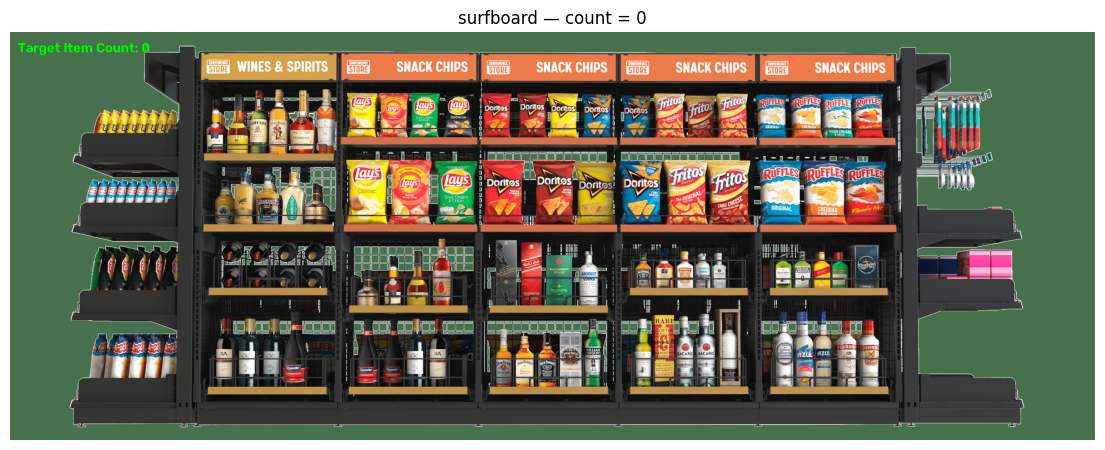

Saved: outputs/task5_retail_filtered.png


In [14]:
out = img.copy()

for box in filtered:
    x1, y1, x2, y2 = map(int, box.xyxy[0].cpu().numpy())
    conf = float(box.conf[0])

    cv2.rectangle(out, (x1, y1), (x2, y2), (0, 255, 0), 2)

    label = f"{model.names[TARGET_CLASS]} {conf:.2f}"
    (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
    cv2.rectangle(out, (x1, y1 - th - 6), (x1 + tw + 4, y1), (0, 255, 0), -1)
    cv2.putText(out, label, (x1 + 2, y1 - 4),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1, cv2.LINE_AA)

# Banner (shadow + color on top for readability on any background)
banner = f"Target Item Count: {target_count}"
cv2.putText(out, banner, (20, 55),
            cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 0), 5, cv2.LINE_AA)
cv2.putText(out, banner, (20, 55),
            cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 255, 0), 2, cv2.LINE_AA)

plt.figure(figsize=(14, 9))
plt.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
plt.title(f"{model.names[TARGET_CLASS]} — count = {target_count}")
plt.axis("off")
plt.show()

cv2.imwrite("../outputs/task5_retail_filtered.png", out)
print("Saved: outputs/task5_retail_filtered.png")